# 06 – Detecting laundering without labels



In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.config import Config
from aml.metrics import recall_at_fpr
from aml.pipeline import run_unsupervised
from aml.plotting import LAUNDERING, MUTED, NORMAL, save, set_style

config = Config()
paths = config.paths
FIG = paths.figures_dir
PROC = paths.processed_dir

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
report = run_unsupervised(config)
step4 = json.loads((paths.reports_dir / "metrics_step4_graph.json").read_text())
scores = pd.read_parquet(PROC / "unsupervised_scores.parquet")
scores.drop(columns="tx_id").groupby("split").mean()

18:23:17 | INFO | aml.unsupervised | day 1: 189,867 communities (4644 with 3+ accounts), 41.4% of the day's payments cross communities
18:23:21 | INFO | aml.unsupervised | day 2: 162,163 communities (9562 with 3+ accounts), 21.0% of the day's payments cross communities
18:23:25 | INFO | aml.unsupervised | day 3: 155,204 communities (8880 with 3+ accounts), 18.2% of the day's payments cross communities
18:23:30 | INFO | aml.unsupervised | day 4: 148,971 communities (8294 with 3+ accounts), 16.4% of the day's payments cross communities
18:23:35 | INFO | aml.unsupervised | day 5: 143,028 communities (7792 with 3+ accounts), 15.0% of the day's payments cross communities
18:23:39 | INFO | aml.unsupervised | day 6: 137,680 communities (7334 with 3+ accounts), 14.7% of the day's payments cross communities
18:23:44 | INFO | aml.unsupervised | day 7: 132,529 communities (6881 with 3+ accounts), 14.4% of the day's payments cross communities
18:23:49 | INFO | aml.unsupervised | day 8: 127,744 com

,is_laundering,score_isolation_forest,score_cross_community,score_community_anomaly,score_combined
split,,,,,
train,0.0008,0.4532,0.5359,0.2072,0.4298
val,0.0011,0.4518,0.1456,0.3535,0.3738
test,0.0011,0.4621,0.1646,0.3395,0.3799


## 1. Crossing communities



In [3]:
cross = pd.DataFrame(report["cross_community"]).T
cross["rate_ratio"] = cross["laundering_rate_crossing"] / cross["laundering_rate_within"]
cross[["share_of_payments_crossing", "share_of_laundering_crossing", "laundering_rate_crossing",
       "laundering_rate_within", "rate_ratio", "roc_auc"]]

,share_of_payments_crossing,share_of_laundering_crossing,laundering_rate_crossing,laundering_rate_within,rate_ratio,roc_auc
train,0.5359,0.8602,0.0012,0.0002,5.3276,0.6623
val,0.1456,0.8283,0.0061,0.0002,28.3037,0.8417
test,0.1646,0.8075,0.0055,0.0003,21.2870,0.8218


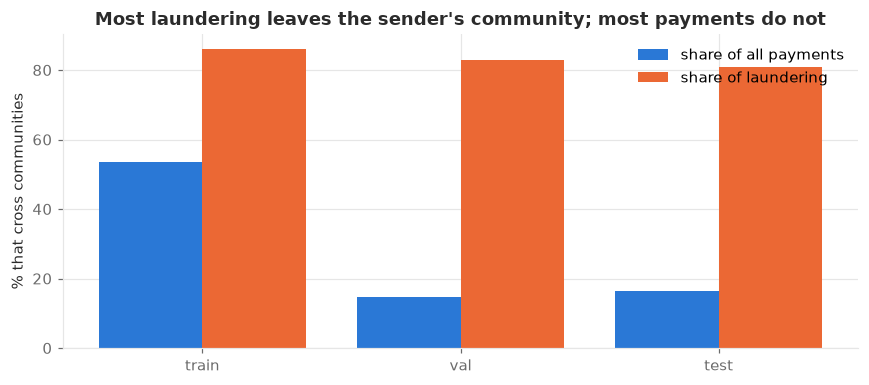

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
splits_ = ["train", "val", "test"]
x = np.arange(len(splits_))
ax.bar(x - 0.2, cross.loc[splits_, "share_of_payments_crossing"] * 100, 0.4, color=NORMAL, label="share of all payments")
ax.bar(x + 0.2, cross.loc[splits_, "share_of_laundering_crossing"] * 100, 0.4, color=LAUNDERING,
       label="share of laundering")
ax.set_xticks(x, splits_)
ax.set_ylabel("% that cross communities")
ax.set_title("Most laundering leaves the sender's community; most payments do not")
ax.legend(loc="upper right")
plt.tight_layout()
save(fig, FIG, "13_cross_community")
plt.show()

In [5]:
y_test = scores.loc[scores["split"] == "test", "is_laundering"].to_numpy()
rows = {}
for name in ["isolation_forest", "community_anomaly", "combined"]:
    r = report[name]
    t, f = r["test"], r["test_by_format"]
    rows[name] = {"PR-AUC": t["pr_auc"], "ROC-AUC": t["roc_auc"],
                  "recall at equal FPR (1%)": t["recall_at_equal_fpr_1pct"],
                  "recall at label-free threshold": t["recall_at_1pct"],
                  "realised FPR": t["fpr_at_1pct"], "alerts": t["alerts_at_1pct"],
                  "recall non-ACH at threshold": f["all other formats"]["recall_at_1pct"]}
t4, f4 = step4["test"], step4["test_by_format"]
graph_scores = pd.read_parquet(PROC / "graph_scores.parquet")
rows["supervised step 4 (reference)"] = {
    "PR-AUC": t4["pr_auc"], "ROC-AUC": t4["roc_auc"],
    "recall at equal FPR (1%)": recall_at_fpr(y_test, graph_scores.loc[graph_scores["split"] == "test", "score"].to_numpy(), 0.01),
    "recall at label-free threshold": t4["recall_at_1pct"], "realised FPR": t4["fpr_at_1pct"],
    "alerts": t4["alerts_at_1pct"], "recall non-ACH at threshold": f4["all other formats"]["recall_at_1pct"]}
unsup_table = pd.DataFrame(rows).T
unsup_table

,PR-AUC,ROC-AUC,recall at equal FPR (1%),recall at label-free threshold,realised FPR,alerts,recall non-ACH at threshold
isolation_forest,0.0024,0.7517,0.0087,0.0691,0.0431,"43,788.0000",0.4306
community_anomaly,0.0012,0.5405,0.0026,0.0026,0.0041,"4,164.0000",0.0208
combined,0.0052,0.8640,0.0227,0.0525,0.0144,"14,714.0000",0.1319
supervised step 4 (reference),0.5669,0.9872,0.8320,0.8381,0.0128,"13,979.0000",0.0000


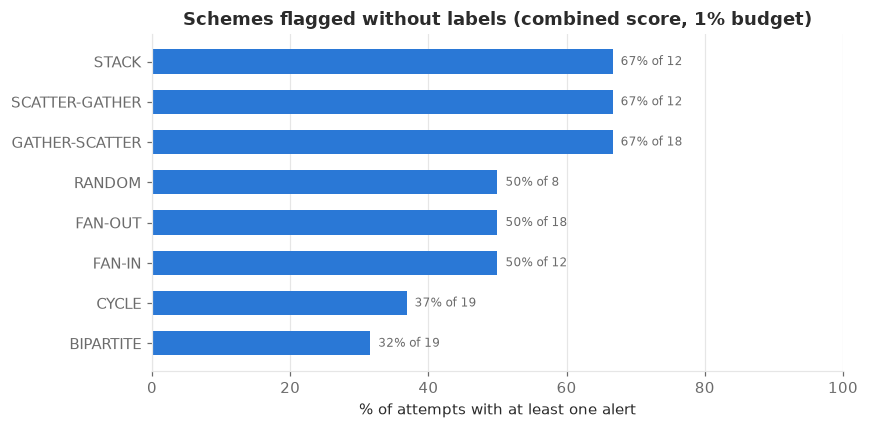

,attempts,attempts_with_any_alert,transaction_recall
BIPARTITE,19.0000,0.3158,0.0959
CYCLE,19.0000,0.3684,0.1336
FAN-IN,12.0000,0.5000,0.1549
FAN-OUT,18.0000,0.5000,0.0850
RANDOM,8.0000,0.5000,0.1917
GATHER-SCATTER,18.0000,0.6667,0.1777
SCATTER-GATHER,12.0000,0.6667,0.1820
STACK,12.0000,0.6667,0.1824


In [6]:
patterns = pd.DataFrame(report["patterns_all_days"]).T.sort_values("attempts_with_any_alert")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(patterns.index, patterns["attempts_with_any_alert"] * 100, color=NORMAL, height=0.6)
for i, (v, n) in enumerate(zip(patterns["attempts_with_any_alert"], patterns["attempts"])):
    ax.text(v * 100, i, f"  {v:.0%} of {int(n)}", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, 100)
ax.set_xlabel("% of attempts with at least one alert")
ax.set_title("Schemes flagged without labels (combined score, 1% budget)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save(fig, FIG, "14_unsupervised_patterns")
plt.show()
patterns

## 5. Collusion groups



In [7]:
recovery = pd.DataFrame(report["group_recovery"]).T
recovery["lift_over_random"] = recovery["share_recovered"] / recovery["random_share"]
recovery

,attempts,share_recovered,all_recovered,median_community_size,random_share,lift_over_random
BIPARTITE,19.0000,0.4681,0.4211,"3,529.0000",0.0111,42.1724
CYCLE,19.0000,0.5497,0.4737,"1,575.0000",0.0078,70.6107
FAN-IN,12.0000,0.5487,0.4167,"2,949.0000",0.0086,63.5527
FAN-OUT,18.0000,0.5552,0.2778,"5,204.5000",0.0124,44.7095
GATHER-SCATTER,18.0000,0.4561,0.3333,"5,544.5000",0.0147,31.0220
RANDOM,8.0000,0.5156,0.5000,"5,483.5000",0.0103,50.2069
SCATTER-GATHER,12.0000,0.5214,0.2500,"1,134.5000",0.0068,77.0921
STACK,12.0000,0.3919,0.3333,"2,322.5000",0.0085,46.3575
all,118.0000,0.5018,0.3729,"1,925.0000",0.0103,48.7187


## 6. Findings

In [8]:
c, cx = unsup_table.loc["combined"], cross.loc["test"]
iso = unsup_table.loc["isolation_forest"]
sup = unsup_table.loc["supervised step 4 (reference)"]
allr = recovery.loc["all"]
lines = [
    f"- **Crossing communities is the strongest label-free signal**: {cx['share_of_payments_crossing']:.0%} of test "
    f"payments cross, but they hold {cx['share_of_laundering_crossing']:.0%} of the laundering "
    f"({cx['rate_ratio']:.0f}x the laundering rate of payments within a community).",
    f"- **Without labels, little is caught at a workable budget**: the combined score catches "
    f"{c['recall at equal FPR (1%)']:.1%} of test laundering at 1% of normal payments flagged "
    f"(ROC-AUC {c['ROC-AUC']:.2f}), against {sup['recall at equal FPR (1%)']:.1%} for the supervised step 4 model.",
    f"- **But it reaches laundering the supervised models miss**: {c['recall non-ACH at threshold']:.0%} of non-ACH "
    f"laundering at its threshold vs {sup['recall non-ACH at threshold']:.0%} for step 4 "
    f"(Isolation Forest alone: {iso['recall non-ACH at threshold']:.0%}, at a much higher alert volume).",
    f"- **Label-free thresholds drift**: 1% of validation payments becomes {iso['realised FPR']:.1%} of normal test "
    f"payments for the Isolation Forest and {c['realised FPR']:.1%} for the combined score.",
    f"- **Schemes**: across all days, {patterns['attempts_with_any_alert'].min():.0%}–"
    f"{patterns['attempts_with_any_alert'].max():.0%} of attempts per pattern type get at least one alert.",
    f"- **Collusion groups**: after one alert, the alerted account's community holds {allr['share_recovered']:.0%} of "
    f"the scheme's other accounts ({allr['lift_over_random']:.0f}x random) and the whole group for "
    f"{allr['all_recovered']:.0%} of schemes, in communities of ~{allr['median_community_size']:,.0f} accounts.",
]
display(Markdown("\n".join(lines)))

- **Crossing communities is the strongest label-free signal**: 16% of test payments cross, but they hold 81% of the laundering (21x the laundering rate of payments within a community).
- **Without labels, little is caught at a workable budget**: the combined score catches 2.3% of test laundering at 1% of normal payments flagged (ROC-AUC 0.86), against 83.2% for the supervised step 4 model.
- **But it reaches laundering the supervised models miss**: 13% of non-ACH laundering at its threshold vs 0% for step 4 (Isolation Forest alone: 43%, at a much higher alert volume).
- **Label-free thresholds drift**: 1% of validation payments becomes 4.3% of normal test payments for the Isolation Forest and 1.4% for the combined score.
- **Schemes**: across all days, 32%–67% of attempts per pattern type get at least one alert.
- **Collusion groups**: after one alert, the alerted account's community holds 50% of the scheme's other accounts (49x random) and the whole group for 37% of schemes, in communities of ~1,925 accounts.